# 03 — Keşifsel Veri Analizi (EDA)

Girdi: `data/processed/arac_temiz_v3.csv`.

Araştırma sorularına bağlı bulgular burada toplanır: (1) etkenler, (3) yaş–fiyat profili, (4) şehir. Soru 3 (yaş–fiyat) ve Soru 4 (şehir) bölümleri aşağıda.


In [1]:
import pandas as pd

# v3 verisini yükle (notebooks klasöründen bir üst dizine çıkılarak)
v3 = pd.read_csv("../data/processed/arac_temiz_v3.csv")

print("--- HİBRİT/ELEKTRİK 'EV' KONTROLÜ ---")
he = v3[v3["yakit_tipi"] == "Hibrit/Elektrik"]
sus = he[~he["variant"].str.upper().str.contains(r"\bEV\b|HYBRID|HIBRIT|ELECTRIC|E-TRON|EQ", regex=True, na=False)]
print(f"Şüpheli (Yanlış Etiketlenmiş) Kayıt Sayısı: {len(sus)}")
if len(sus) > 0:
    print(sus["variant"].value_counts().head(20))

print("\n--- BİLİNMİYOR YAKIT ÖRNEKLEMİ (40 ADET) ---")
bil = v3[v3["yakit_tipi"] == "Bilinmiyor"]
if len(bil) > 0:
    print(bil[["brand", "model", "variant"]].sample(min(40, len(bil)), random_state=7))

print("\n--- ŞEHİR VE RENK DAĞILIMI ---")
print(f"Benzersiz Şehir Sayısı: {v3['city'].nunique()}")
print("Şehir Listesi:", sorted(v3["city"].dropna().unique()))
print("\nRenk Dağılımı:")
print(v3["color"].value_counts())

--- HİBRİT/ELEKTRİK 'EV' KONTROLÜ ---
Şüpheli (Yanlış Etiketlenmiş) Kayıt Sayısı: 466
variant
i5 eDrive 40                             123
i4 eDrive 40                              85
1.5 Mhev Premium                          60
i7 xDrive60 M Excellence                  46
i8 Premium Techno                         40
1.5 Mhev Elite                            32
230e xDrive Active Tourer Luxury Line     27
i5 M60 xDrive                             24
i4 M50                                    16
i5 xDrive40                               13
Name: count, dtype: int64

--- BİLİNMİYOR YAKIT ÖRNEKLEMİ (40 ADET) ---
             brand     model                    variant
61721         fiat     panda                1.2 Dynamic
68743         ford    fiesta               1.6 Titanium
174698     renault    megane                    1.6 Joy
149242     porsche    taycan        4S Performance Plus
200760       tesla     model               RWD (Legacy)
134445        opel     corsa                  1.

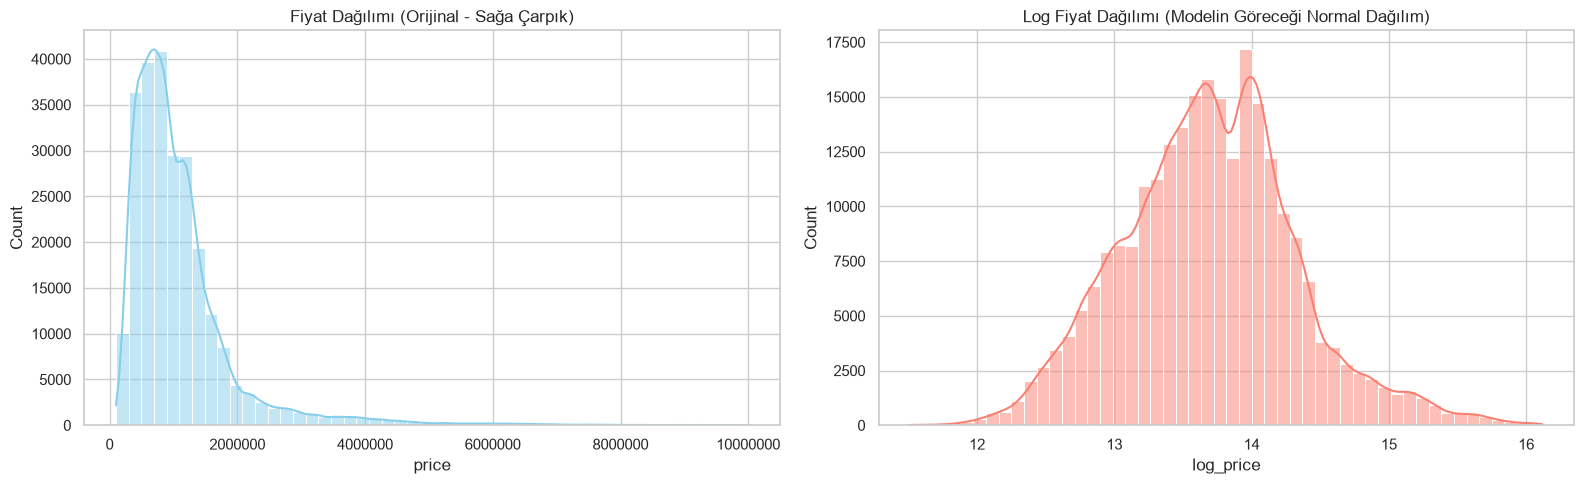

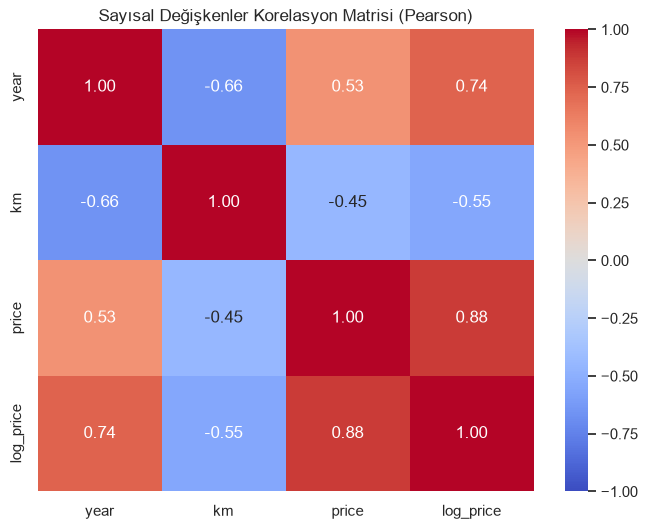

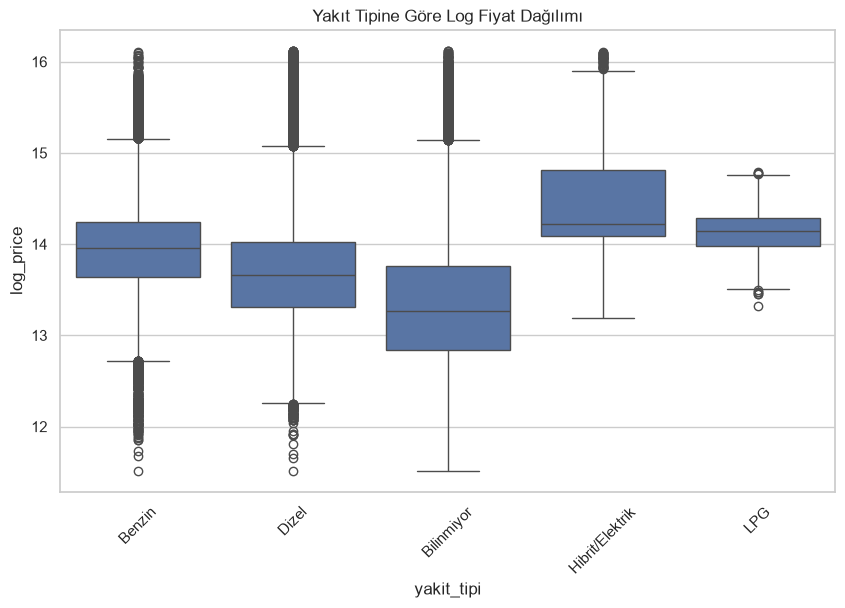

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Görsel ayarları
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Temizlenmiş veriyi yükle (Notebook içinden çalıştırıldığı için ../ kullanıldı)
df = pd.read_csv("../data/processed/arac_temiz_v3.csv")

# 1. Hedef Değişken (Fiyat) Dağılımı Orijinal vs Logaritmik
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.histplot(df['price'], bins=50, ax=axes[0], color='skyblue', kde=True)
axes[0].set_title('Fiyat Dağılımı (Orijinal - Sağa Çarpık)')
axes[0].ticklabel_format(style='plain', axis='x')

sns.histplot(df['log_price'], bins=50, ax=axes[1], color='salmon', kde=True)
axes[1].set_title('Log Fiyat Dağılımı (Modelin Göreceği Normal Dağılım)')
plt.tight_layout()
plt.show()

# 2. Sayısal Değişkenlerin Korelasyon Matrisi
num_cols = ['year', 'km', 'price', 'log_price']
corr = df[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Sayısal Değişkenler Korelasyon Matrisi (Pearson)')
plt.show()

# 3. Yakıt Tipine Göre Fiyat Dağılımı (Kutu Grafiği)
plt.figure(figsize=(10, 6))
sns.boxplot(x='yakit_tipi', y='log_price', data=df)
plt.title('Yakıt Tipine Göre Log Fiyat Dağılımı')
plt.xticks(rotation=45)
plt.show()

## Ortak hazırlık: sabit etkili (fixed effects) regresyon

Ham ortalamalar yanıltıcıdır: eski araçlar ve bazı şehirlerdeki araçlar zaten farklı modellerdir.
Bu yüzden karşılaştırmaları **aynı varyant içinde** yapıyoruz: her değişkenden kendi grubunun ortalaması çıkarılır
(grup içi dönüşüm), sonra kalan farklar üzerinde en küçük kareler kurulur. Bu, her varyant için ayrı bir sabit terim koymakla eşdeğerdir.

Yaş = 2025 − model yılı (veri Aralık 2025 kesiti). km 10.000 km birimindedir.

In [3]:
import numpy as np

df["yas"] = 2025 - df["year"]
df["km10k"] = df["km"] / 10_000
VARYANT = ["brand", "model", "variant"]

def grup_ici(d, sutunlar, gruplar):
    """Her sütundan kendi grubunun ortalamasını çıkarır (sabit etki dönüşümü)."""
    return d[sutunlar] - d.groupby(gruplar)[sutunlar].transform("mean")

def ekk(X, y):
    """En küçük kareler: katsayı, standart hata, artık."""
    b, *_ = np.linalg.lstsq(X, y, rcond=None)
    r = y - X @ b
    s2 = r @ r / (len(y) - X.shape[1])
    se = np.sqrt(np.diag(s2 * np.linalg.pinv(X.T @ X)))
    return b, se, r

## Soru 3 — Marka bazında yaş–fiyat (değer kaybı) profili

Model (her marka için ayrı): `log_price ~ yas + km10k + km_kirpildi + varyant sabit etkisi`.
`yas` katsayısı b ise yıllık değer kaybı = 1 − e^b. Yani **aynı varyant ve aynı km'de** bir yaş büyümenin fiyata etkisi.
En çok ilanı olan 10 marka.

,marka,ilan,yillik_kayip_%,alt_%,ust_%,10bin_km_etkisi_%
9,hyundai,11088,2.43,2.27,2.58,-1.59
2,fiat,23698,2.94,2.85,3.04,-1.56
7,toyota,11884,3.44,3.29,3.59,-1.40
3,opel,19966,3.87,3.78,3.95,-1.52
0,renault,35971,4.15,4.07,4.23,-1.50
5,ford,15835,4.55,4.45,4.66,-1.67
1,volkswagen,35714,5.13,5.07,5.20,-1.60
4,bmw,17945,5.74,5.65,5.84,-1.87
8,audi,11164,5.99,5.86,6.12,-1.60
6,mercedes,13873,6.01,5.91,6.12,-1.69


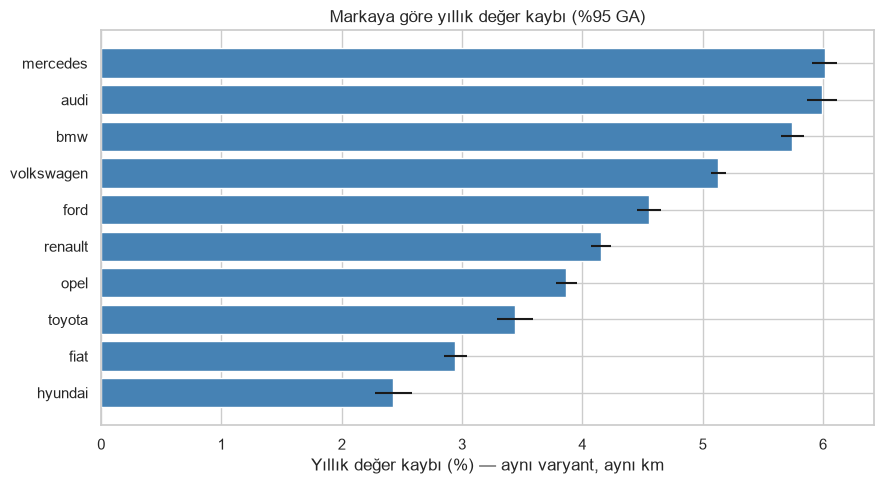

In [4]:
satirlar = []
for marka in df["brand"].value_counts().head(10).index:
    d = df[df["brand"] == marka]
    Z = grup_ici(d, ["log_price", "yas", "km10k", "km_kirpildi"], [d[k] for k in VARYANT])
    b, se, _ = ekk(Z[["yas", "km10k", "km_kirpildi"]].values, Z["log_price"].values)
    satirlar.append({"marka": marka, "ilan": len(d),
                     "yillik_kayip_%": (1 - np.exp(b[0])) * 100,
                     "alt_%": (1 - np.exp(b[0] + 1.96 * se[0])) * 100,
                     "ust_%": (1 - np.exp(b[0] - 1.96 * se[0])) * 100,
                     "10bin_km_etkisi_%": (np.exp(b[1]) - 1) * 100})
deger_kaybi = pd.DataFrame(satirlar).sort_values("yillik_kayip_%")
display(deger_kaybi.round(2))

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(deger_kaybi["marka"], deger_kaybi["yillik_kayip_%"], color="steelblue",
        xerr=[deger_kaybi["yillik_kayip_%"] - deger_kaybi["alt_%"], deger_kaybi["ust_%"] - deger_kaybi["yillik_kayip_%"]])
ax.set_xlabel("Yıllık değer kaybı (%) — aynı varyant, aynı km")
ax.set_title("Markaya göre yıllık değer kaybı (%95 GA)")
plt.tight_layout(); plt.show()

Doğrusal yaş varsayımını kontrol etmek için yaşı kategorik alıp (0–20, 20+ birleştirildi) profili çiziyoruz.
Değerler aynı varyant ve km'de, **yaş 1'e göre** fiyat oranıdır.

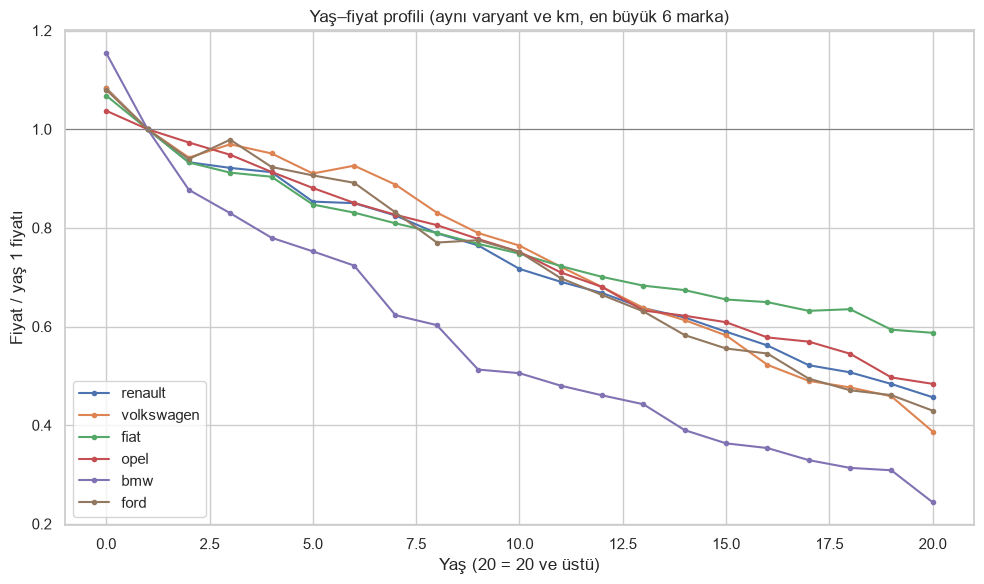

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))
for marka in df["brand"].value_counts().head(6).index:
    d = df[df["brand"] == marka].copy()
    d["yas_k"] = d["yas"].clip(upper=20)
    D = pd.get_dummies(d["yas_k"], prefix="y", dtype=float).drop(columns="y_1")
    g = [d[k] for k in VARYANT]
    Z = grup_ici(d.join(D), ["log_price", "km10k", "km_kirpildi"] + list(D.columns), g)
    b, _, _ = ekk(Z[["km10k", "km_kirpildi"] + list(D.columns)].values, Z["log_price"].values)
    profil = pd.Series(np.exp(b[2:]), index=[int(c[2:]) for c in D.columns])
    profil.loc[1] = 1.0
    ax.plot(profil.sort_index(), marker="o", ms=3, label=marka)
ax.axhline(1, color="gray", lw=0.8)
ax.set_xlabel("Yaş (20 = 20 ve üstü)"); ax.set_ylabel("Fiyat / yaş 1 fiyatı")
ax.set_title("Yaş–fiyat profili (aynı varyant ve km, en büyük 6 marka)")
ax.legend(); plt.tight_layout(); plt.show()

**Bulgu (taslak — kendi sözlerinle yaz):** Aynı varyant ve km'de yıllık değer kaybı Hyundai'de yaklaşık %2,4, Fiat'ta %2,9 iken
BMW, Audi ve Mercedes'te %5,7–6,0. Premium markalar daha hızlı değer kaybediyor. 10.000 km'nin etkisi markalar arasında
benzer (yaklaşık −%1,4 ile −%1,9). Profil grafiğinde eğrinin doğrusal olup olmadığına bak ve yorumla.

⚠ Standart hatalar klasik EKK hatasıdır; aynı varyanttaki ilanlar bağımsız olmadığı için gerçek belirsizlik daha büyüktür
(varyant düzeyinde kümelenmiş hata). Markalar arası fark, aralıklardan çok daha büyük olduğu için sonuç değişmez; tezde belirt.

⚠ **Nesil karışması:** Varyant adı farklı kasa nesillerinde aynı kalabiliyor (ör. BMW "320i": E90, F30, G20; VW "Golf 1.6"). Bu durumda "yaş etkisi" saf yıpranmayı değil, eski nesil olmanın etkisini de içerir. Premium markalardaki daha dik eğrinin bir kısmı bundan kaynaklanabilir. Bu bir sınırlılık olarak belirtilmeli; veride kasa/nesil bilgisi yok.

## Soru 4 — Şehir, diğer özellikler sabitken fiyatı etkiliyor mu?

Model: `log_price ~ km10k + km_kirpildi + şehir + (varyant × model yılı) sabit etkisi`. Referans il: İstanbul.
Katsayı, **aynı varyant ve aynı model yılındaki** bir aracın o ilde İstanbul'a göre yüzde kaç farklı fiyatlandığını gösterir.
Karşılaştırma için ham medyan fiyat farkı da verildi.

In [6]:
g = [df[k] for k in VARYANT + ["year"]]
Z = grup_ici(df, ["log_price", "km10k", "km_kirpildi"], g)
D = pd.get_dummies(df["city"], dtype=float).drop(columns="İstanbul")
Dz = D - D.groupby(g).transform("mean")
y = Z["log_price"].values
X0 = Z[["km10k", "km_kirpildi"]].values
X1 = np.column_stack([X0, Dz.values])
b1, se1, r1 = ekk(X1, y)
_, _, r0 = ekk(X0, y)

# Şehirlerin birlikte anlamlılığı: F testi (şehirsiz model vs şehirli model)
q = D.shape[1]
sd = len(y) - X1.shape[1] - df.groupby(g).ngroups
F = ((r0 @ r0 - r1 @ r1) / q) / (r1 @ r1 / sd)
print(f"F({q}, {sd}) = {F:.1f}   (%5 kritik değer ≈ 1,26)")
print(f"Şehirlerin açıkladığı ek grup içi varyans: %{(r0 @ r0 - r1 @ r1) / (y @ y) * 100:.1f}")

istanbul_medyan = df.loc[df["city"] == "İstanbul", "price"].median()
sehir = pd.DataFrame({"il": D.columns,
                      "ilan": D.sum().values.astype(int),
                      "kontrollu_fark_%": (np.exp(b1[2:]) - 1) * 100,
                      "se_%": se1[2:] * 100})
sehir["ham_medyan_fark_%"] = sehir["il"].map(df.groupby("city")["price"].median() / istanbul_medyan * 100 - 100)
sehir = sehir.sort_values("kontrollu_fark_%")
display(sehir[sehir["ilan"] >= 3000].round(2))

F(80, 239866) = 145.6   (%5 kritik değer ≈ 1,26)
Şehirlerin açıkladığı ek grup içi varyans: %3.2


,il,ilan,kontrollu_fark_%,se_%,ham_medyan_fark_%
33,Hatay,4437,-5.18,0.17,-11.62
78,Şanlıurfa,4278,-0.77,0.18,-6.57
22,Diyarbakır,3340,-0.58,0.20,-1.52
29,Gaziantep,7415,-0.24,0.14,-9.09
0,Adana,6104,0.18,0.15,-15.66
43,Kocaeli,7455,2.13,0.14,-17.27
77,İzmir,12741,2.56,0.11,-16.16
65,Tekirdağ,3306,2.57,0.20,-17.68
20,Bursa,9830,2.67,0.12,-14.24
6,Antalya,9967,3.03,0.12,-11.62


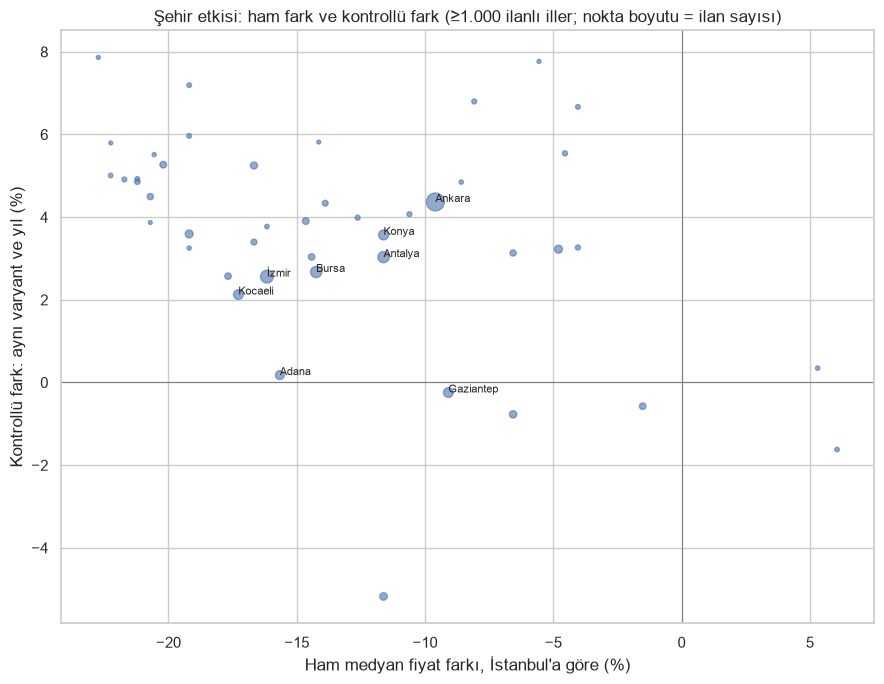

In [7]:
s = sehir[sehir["ilan"] >= 1000]
fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(s["ham_medyan_fark_%"], s["kontrollu_fark_%"], s=s["ilan"] / 150, alpha=0.6)
for _, r in s[s["ilan"] >= 5000].iterrows():
    ax.annotate(r["il"], (r["ham_medyan_fark_%"], r["kontrollu_fark_%"]), fontsize=8)
ax.axhline(0, color="gray", lw=0.8); ax.axvline(0, color="gray", lw=0.8)
ax.set_xlabel("Ham medyan fiyat farkı, İstanbul'a göre (%)")
ax.set_ylabel("Kontrollü fark: aynı varyant ve yıl (%)")
ax.set_title("Şehir etkisi: ham fark ve kontrollü fark (≥1.000 ilanlı iller; nokta boyutu = ilan sayısı)")
plt.tight_layout(); plt.show()

**Bulgu (taslak — kendi sözlerinle yaz):** Ham veride İstanbul diğer illerin çoğundan pahalı görünüyor, ancak aynı varyant,
model yılı ve km'de tablo tersine dönüyor: İstanbul en ucuz illerden biri, illerin büyük çoğunluğu yaklaşık %2–8 daha pahalı
(Ankara ≈ +%4,4). Ham fark büyük ölçüde **kompozisyon etkisi**: İstanbul'da daha yeni/pahalı araçlar ilana çıkıyor.
Şehirler birlikte istatistiksel olarak anlamlı (F testi), fakat etki büyüklüğü küçük: grup içi varyansın yalnızca ~%3'ünü açıklıyorlar.
Hatay (≈ −%5) ve Kilis (≈ −%10) belirgin biçimde ucuz; nedeni bu veriyle bilinemez (deprem sonrası araç piyasası ya da
hasarlı araç oranı gibi açıklamalar yalnızca hipotezdir).

⚠ 250 bin gözlemle neredeyse her fark "anlamlı" çıkar; tezde anlamlılık yerine **etki büyüklüğünü** vurgula.
⚠ Standart hatalar kümelenmemiş; ilan sayısı az illerde (Kilis, Bartın vb.) sonuçları ihtiyatla yorumla.
⚠ Kesin cevap modelleme aşamasında: şehirli ve şehirsiz modelin tahmin hatası ile SHAP'ta şehrin payı karşılaştırılacak.